In [1]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import NDArray
from typing import Tuple
from mcap.reader import make_reader
from mcap_ros2.decoder import DecoderFactory

In [2]:
mcap_file_path_outer = "../data/Maps/own_outer_0.mcap"
mcap_file_path_inner_1 = "../data/Maps/own_inner_10.mcap"
mcap_file_path_inner_2 = "../data/Maps/own_inner_20.mcap"

In [3]:
with open(mcap_file_path_outer, "rb") as f:
    reader = make_reader(f)

    # 1. Zusammenfassung der Datei laden
    summary = reader.get_summary()

    if summary:
        print("--- ALLGEMEINE STATISTIKEN ---")
        stats = summary.statistics
        print(f"Nachrichten insgesamt: {stats.message_count}")
        print(f"Anzahl Kanäle/Topics: {stats.channel_count}")
        print(f"Startzeit (Nanosekunden): {stats.message_start_time}")
        print(f"Endzeit (Nanosekunden): {stats.message_end_time}")

        print("\n--- REGISTRIERTE SCHEMATA (Datentypen) ---")
        for schema_id, schema in summary.schemas.items():
            print(f"ID {schema_id}: {schema.name} (Typ: {schema.encoding})")

        print("\n--- AKTIVE KANÄLE (Topics) ---")
        for channel_id, channel in summary.channels.items():
            # Zugehöriges Schema finden
            schema_name = summary.schemas[channel.schema_id].name if channel.schema_id in summary.schemas else "Kein Schema"
            print(f"Topic: '{channel.topic}' | Typ: {schema_name} | Encoding: {channel.message_encoding}")
    else:
        print("Die Datei enthält keine Summary-Sektion. Sie muss sequenziell gescannt werden.")

--- ALLGEMEINE STATISTIKEN ---
Nachrichten insgesamt: 11315
Anzahl Kanäle/Topics: 1
Startzeit (Nanosekunden): 1794331466429946992
Endzeit (Nanosekunden): 1794331522040454547

--- REGISTRIERTE SCHEMATA (Datentypen) ---
ID 1: tf2_msgs/msg/TFMessage (Typ: ros2msg)

--- AKTIVE KANÄLE (Topics) ---
Topic: '/tf' | Typ: tf2_msgs/msg/TFMessage | Encoding: cdr


In [4]:
def decode_msg(path: str, get_data: bool) -> Tuple[NDArray, NDArray] | Tuple[None, None]:
    x = []
    y = []

    with open(path, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])

        for i, (schema, channel, message, msg) in enumerate(
            reader.iter_decoded_messages(topics=["/tf"])
        ):
            data = msg.transforms[-1]
            vec = data.transform.translation

            if get_data:
                pass
                x.append(vec.x)
                y.append(vec.y)
            else:
                print(f"\nMessage {i}")
                # print(schema)
                #print(channel)
                #print(message)
                # print(msg)

                #for i in range(len(msg.transforms)):
                #    print(f"\n{i}: {msg.transforms[i]}")

                #ata = msg.transforms[-1]
                #vec = data.transform.translation.x

                print(vec)

                #print("\n")
                #print(f"Timestamp: {msg.transforms[0]}")

                # print(f"Reference frame: {msg.header.frame_id}")
                # print(f"Tracked frame:   {msg.child_frame_id}")
                # print(f"Stamp: {msg.header.stamp.sec} s + "
                #       f"{msg.header.stamp.nanosec} ns")
                # print(f"Position: x={position.x}, y={position.y}, z={position.z}")
                # print(f"Orientation: x={orientation.x}, y={orientation.y}, "
                #       f"z={orientation.z}, w={orientation.w}")

                if i >= 0:
                    break

    if get_data:
        return np.array(x), np.array(y)
    else:
        return None, None

decode_msg(mcap_file_path_outer, False)


Message 0
Vector3(x=1.280249834060669, y=2.034902334213257, z=0.06517207622528076)


(None, None)

In [5]:
x_outer, y_outer = decode_msg(mcap_file_path_outer, True)

x_inner_1, y_inner_1 = decode_msg(mcap_file_path_inner_1, True)

x_inner_2, y_inner_2 = decode_msg(mcap_file_path_inner_2, True)

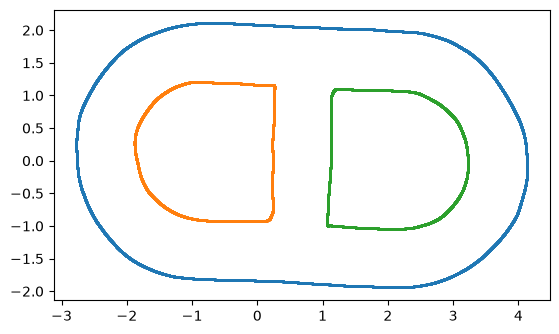

In [7]:
plt.scatter(x_outer, y_outer, s=1)
plt.scatter(x_inner_1, y_inner_1, s=1)
plt.scatter(x_inner_2, y_inner_2, s=1)

plt.gca().set_aspect("equal", adjustable="box")